Logistic Regression -> 88.20%
SVC -> 87.20%
KNN -> 81.40%
Decision Tree -> 76.40%
Random Forest -> 83.40%
Naive Bayes -> 84.20%
Imagen guardada como evaluacion_algoritmos.png


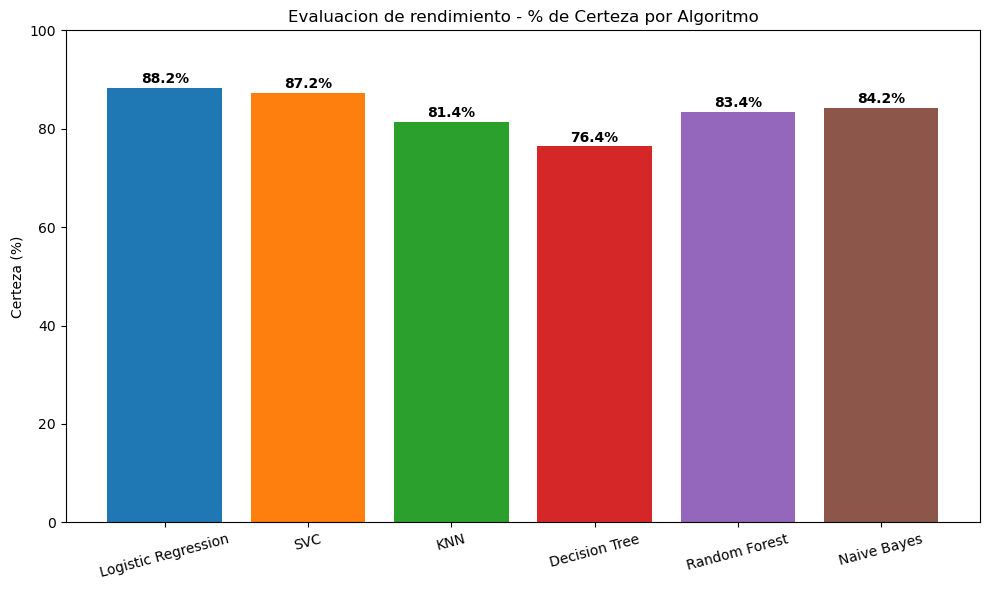

In [3]:
#-----------------------------------------------------------------------------------------
#  Proposito : Dada la informacion obtenida en internet sobre  factores de riesgo de cancer  se hacen los sigueinets pasos,
#              es importante aclarar que en esta evaluacion de datos se maneja informacion etiquetada
#              1. se carga la informacion 
#              2, se divide la informacion 75% para entrenamiento y   
#                                          25% para evaluacion
#              3. la evaluacion de la informacion se realizara para los algoritmos especializado en datos etiquetados como
#                 3.1 Regresion logistica
#                 3.2 SVC
#                 3.3 KNN
#                 3.4 Arbol de desiciones
#                 3.5 Random Forest
#                 3.6 Naive Bayes
#              4. Medicion de metricas de rendimiento cuyo proposito busca establecer le resultado de certeza por cada algoritmo y  
#                 y presentarlo para seleccion del algoritmo que sera o seran seleccionados como candidatos

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# 1. CARGAR Y DEFINIR ETIQUETA
df = pd.read_csv('cancer-risk-factors.csv')
X = df.drop(columns=['Patient_ID','Risk_Level','Overall_Risk_Score','Cancer_Type'], errors='ignore')
X = pd.get_dummies(X, drop_first=True)
y = df['Risk_Level'] # <-- CAMPO ETIQUETADO

# 2. PARCELAR 1500 y 500
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=1500, test_size=500, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. LISTA DE ALGORITMOS
modelos = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "SVC": SVC(),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Naive Bayes": GaussianNB()
}

# 4. ESTAS DOS LISTAS VAN AFUERA, ANTES DE EMPEZAR
nombres = []
certezas = []

# 5. AQUÍ SE EJECUTA ALGORITMO POR ALGORITMO
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, pred) * 100
    nombres.append(nombre)  # Va guardando
    certezas.append(acc)    # Va guardando
    print(f"{nombre} -> {acc:.2f}%")

# 6. ¡LA GRÁFICA VA AQUÍ AFUERA! DESPUÉS DE QUE EL FOR YA TERMINÓ
# Si la mete dentro del for, solo pinta el último y le queda ese pegote azul
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
plt.figure(figsize=(10,6))
bars = plt.bar(nombres, certezas, color=colores)
plt.ylim(0, 100)
plt.ylabel('Certeza (%)')
plt.title('Evaluacion de rendimiento - % de Certeza por Algoritmo')
plt.xticks(rotation=15)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1, f'{h:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()

# <<< AQUÍ PARCE, JUSTO AQUÍ VA, para grabar >>>
plt.savefig("evaluacion_algoritmos.png", dpi=300, bbox_inches='tight')
print("Imagen guardada como evaluacion_algoritmos.png")


plt.show()